# 02 · POS Tagging con spaCy y NLTK

**Etapa 3 del pipeline:** etiquetado de categorías gramaticales de las reseñas en español.

Se usan dos herramientas:

1. **spaCy** y **NLTK**


## Preparación del entorno


```bash
pip install -r requirements.txt
python -m spacy download es_core_news_md
```


In [2]:
import sys
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Raíz del proyecto: el notebook se ejecuta desde la carpeta notebooks/
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import pos_tagging as pt

RUTA_LIMPIAS = RAIZ / "data" / "processed" / "resenas_limpias.csv"
DIR_RESULTADOS = RAIZ / "data" / "results"
RUTA_POS = DIR_RESULTADOS / "pos_analysis.csv"
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

resenas = pd.read_csv(RUTA_LIMPIAS)
print(f"{len(resenas)} reseñas cargadas de {RUTA_LIMPIAS.relative_to(RAIZ)}")

3000 reseñas cargadas de data\processed\resenas_limpias.csv


## 1. Etiquetado con spaCy

### 1.1 Carga del modelo

Se carga `es_core_news_md`

In [5]:
# tuve que ejecutar python -m spacy download es_core_news_md
nlp = pt.cargar_spacy()
print("Modelo:", nlp.meta["lang"] + "_" + nlp.meta["name"], nlp.meta["version"])
print("Componentes activos:", nlp.pipe_names)

Modelo: es_core_news_md 3.8.0
Componentes activos: ['tok2vec', 'morphologizer', 'parser', 'attribute_ruler', 'lemmatizer']


In [6]:
oracion_ejemplo = "No me gustó nada: la película es demasiado larga y el final, muy predecible."
doc = nlp(oracion_ejemplo)

print(f'Oración: "{oracion_ejemplo}"\n')
print(f"{'Token':<12} {'POS':<6} {'Tag':<6} {'Lema':<12} Morfología")
print("-" * 70)
for token in doc:
    print(f"{token.text:<12} {token.pos_:<6} {token.tag_:<6} {token.lemma_:<12} {token.morph}")

Oración: "No me gustó nada: la película es demasiado larga y el final, muy predecible."

Token        POS    Tag    Lema         Morfología
----------------------------------------------------------------------
No           ADV    ADV    no           Polarity=Neg
me           PRON   PRON   yo           Case=Dat|Number=Sing|Person=1|PrepCase=Npr|PronType=Prs
gustó        VERB   VERB   gustar       Mood=Ind|Number=Sing|Person=3|Tense=Past|VerbForm=Fin
nada         PRON   PRON   nada         Number=Sing|PronType=Neg
:            PUNCT  PUNCT  :            PunctType=Colo
la           DET    DET    el           Definite=Def|Gender=Fem|Number=Sing|PronType=Art
película     NOUN   NOUN   película     Gender=Fem|Number=Sing
es           AUX    AUX    ser          Mood=Ind|Number=Sing|Person=3|Tense=Pres|VerbForm=Fin
demasiado    ADV    ADV    demasiado    
larga        ADJ    ADJ    largo        Gender=Fem|Number=Sing
y            CCONJ  CCONJ  y            
el           DET    DET    el      

### 1.3 Etiquetado del corpus completo

`pt.etiquetar_spacy` procesa las 3.000 reseñas **por lotes** con `nlp.pipe` (mucho más rápido que llamar a `nlp` reseña por reseña) y guarda **un token por fila**, con el identificador de la reseña y el número de oración. En CPU tarda unos minutos.

In [7]:
inicio = time.time()
tokens = pt.etiquetar_spacy(resenas["id"], resenas["texto_es"], nlp, batch_size=64)
print(f"Etiquetado en {(time.time() - inicio) / 60:.1f} min")
print(f"{len(tokens):,} tokens · {tokens.groupby('id')['oracion'].nunique().sum():,} oraciones · "
      f"{tokens['id'].nunique()} reseñas")
tokens.head(10)

C:\Users\ale23\Desktop\CUC\REPOS-CUC\ProyectoExploracion\MineriaDatos\src\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 3000/3000 [01:06<00:00, 45.14reseña/s]


Etiquetado en 1.1 min
639,598 tokens · 30,607 oraciones · 3000 reseñas


,id,oracion,token,lema,upos_spacy,tag_spacy,morf
0,1,0,Lo,él,PRON,PRON,Case=Acc|Definite=Def|Gender=Masc|Number=Sing|...
1,1,0,bueno,bueno,ADJ,ADJ,Gender=Masc|Number=Sing
2,1,0,:,:,PUNCT,PUNCT,PunctType=Colo
3,1,0,La,el,DET,DET,Definite=Def|Gender=Fem|Number=Sing|PronType=Art
4,1,0,comedia,comedia,NOUN,NOUN,Gender=Fem|Number=Sing
5,1,0,",",",",PUNCT,PUNCT,PunctType=Comm
6,1,0,Drama,Drama,PROPN,PROPN,
7,1,0,",",",",PUNCT,PUNCT,PunctType=Comm
8,1,0,Psicología,Psicología,PROPN,PROPN,
9,1,0,",",",",PUNCT,PUNCT,PunctType=Comm


In [8]:
assert tokens["id"].nunique() == len(resenas), "Alguna reseña quedó sin tokens"
print("Distribución UPOS de spaCy (% de tokens):")
(tokens["upos_spacy"].value_counts(normalize=True) * 100).round(2).to_frame("%")

Distribución UPOS de spaCy (% de tokens):


,%
upos_spacy,
NOUN,16.22
PUNCT,12.84
DET,12.34
ADP,11.67
VERB,9.12
ADJ,7.34
PRON,6.30
ADV,6.15
AUX,5.27


## 2. Etiquetador en español con NLTK

### 2.1 El corpus `cess_esp` y el esquema EAGLES



| Etiqueta | Significado |
|---|---|
| `ncms000` | **n**ombre **c**omún, **m**asculino, **s**ingular |
| `vmip3s0` | **v**erbo **m**ain (principal), **i**ndicativo, **p**resente, **3**.ª persona, **s**ingular |
| `aq0fs0` | **a**djetivo **q**ualificativo, **f**emenino, **s**ingular |
| `sps00` | preposición (**s**) |
| `Fc` | puntuación: coma |

In [9]:
pt.asegurar_recursos_nltk(("corpora/cess_esp",))
from nltk.corpus import cess_esp

print(f"Oraciones en cess_esp: {len(cess_esp.tagged_sents()):,}")
print(f"Palabras: {len(cess_esp.tagged_words()):,}\n")
print("Primera oración con sus etiquetas EAGLES:")
for palabra, etiqueta in cess_esp.tagged_sents()[0][:15]:
    print(f"  {palabra:<15} → {etiqueta}")

Oraciones en cess_esp: 6,030
Palabras: 192,686

Primera oración con sus etiquetas EAGLES:
  El              → da0ms0
  grupo           → ncms000
  estatal         → aq0cs0
  Electricité_de_France → np00000
  -Fpa-           → Fpa
  EDF             → np00000
  -Fpt-           → Fpt
  anunció         → vmis3s0
  hoy             → rg
  ,               → Fc
  jueves          → W
  ,               → Fc
  la              → da0fs0
  compra          → ncfs000
  del             → spcms


### 2.2 Conversión EAGLES → UPOS

spaCy etiqueta con UPOS, así que las etiquetas EAGLES se convierten con `pt.eagles_a_upos`, a partir de la primera letra de cada código




In [10]:
# Ejemplos de la conversión
for etiqueta in ["ncms000", "np0000p", "vmip3s0", "vsip3s0", "vaip3s0", "aq0fs0",
                 "rg", "sps00", "da0ms0", "pp1cs000", "cc", "cs", "Fc", "Z"]:
    print(f"  {etiqueta:<10} → {pt.eagles_a_upos(etiqueta)}")

  ncms000    → NOUN
  np0000p    → PROPN
  vmip3s0    → VERB
  vsip3s0    → AUX
  vaip3s0    → AUX
  aq0fs0     → ADJ
  rg         → ADV
  sps00      → ADP
  da0ms0     → DET
  pp1cs000   → PRON
  cc         → CCONJ
  cs         → SCONJ
  Fc         → PUNCT
  Z          → NUM


In [11]:
oraciones_cess = pt.oraciones_cess_upos()

print("Primera oración convertida a UPOS:")
print(oraciones_cess[0][:15], "\n")
print("Distribución UPOS en cess_esp (% de palabras):")
upos_cess = Counter(etiqueta for oracion in oraciones_cess for _, etiqueta in oracion)
(pd.Series(upos_cess).sort_values(ascending=False) / sum(upos_cess.values()) * 100).round(2).to_frame("%")

Primera oración convertida a UPOS:
[('el', 'DET'), ('grupo', 'NOUN'), ('estatal', 'ADJ'), ('electricité_de_france', 'PROPN'), ('-fpa-', 'PUNCT'), ('edf', 'PROPN'), ('-fpt-', 'PUNCT'), ('anunció', 'VERB'), ('hoy', 'ADV'), (',', 'PUNCT'), ('jueves', 'NUM'), (',', 'PUNCT'), ('la', 'DET'), ('compra', 'NOUN'), ('del', 'ADP')] 

Distribución UPOS en cess_esp (% de palabras):


,%
NOUN,17.87
ADP,15.20
DET,14.53
PUNCT,12.80
VERB,9.54
ADJ,7.26
PROPN,5.29
PRON,4.51
ADV,3.85
CCONJ,3.10


### 2.3 Entrenamiento y evaluación: unigrama y bigrama

`pt.entrenar_etiquetadores` usa el 90 % inicial de las oraciones para entrenar y el 10 % final para evaluar:


In [12]:
modelos_nltk = pt.entrenar_etiquetadores(oraciones_cess)

print(f"Oraciones de entrenamiento: {modelos_nltk['n_entreno']:,} · prueba: {modelos_nltk['n_prueba']:,}\n")
exactitud = pd.Series(modelos_nltk["exactitud"], name="exactitud")
(exactitud * 100).round(2).astype(str).add(" %").to_frame()

Oraciones de entrenamiento: 5,427 · prueba: 603



,exactitud
Por defecto (todo NOUN),18.06 %
Unigrama,86.22 %
Bigrama con respaldo,87.61 %


**Interpretación:** el bigrama debería superar al unigrama, aunque por poco. La mayor parte de los aciertos viene de las palabras frecuentes, y el contexto de una sola palabra anterior solo resuelve parte de la ambigüedad. Para etiquetar el corpus de reseñas se usa el **bigrama con respaldo**, que es el de mayor exactitud.


### 2.4 Etiquetado del corpus con NLTK

`pt.etiquetar_nltk` etiqueta **los mismos tokens que produjo spaCy**: así ambas herramientas analizan exactamente las mismas unidades, condición indispensable para compararlas. Los tokens se agrupan por oración para que el bigrama use como contexto la palabra anterior de la misma oración.



In [13]:
inicio = time.time()
tokens["upos_nltk"] = pt.etiquetar_nltk(tokens, modelos_nltk["bigrama"])
tokens["en_cess"] = tokens["token"].str.lower().isin(modelos_nltk["vocabulario"])
print(f"Etiquetado en {time.time() - inicio:.1f} s")

sin_puntuacion = tokens[tokens["upos_spacy"] != "PUNCT"]
print(f"Tokens (sin puntuación) ausentes del entrenamiento de NLTK: "
      f"{(~sin_puntuacion['en_cess']).mean() * 100:.1f} %")

Etiquetado en 1.7 s
Tokens (sin puntuación) ausentes del entrenamiento de NLTK: 13.6 %


### 2.5 Comparación

Como en la demo de clase, se comparan las etiquetas de ambas herramientas en una misma oración.

In [14]:
def comparar_oracion(id_resena, n_oracion):
    oracion = tokens[(tokens["id"] == id_resena) & (tokens["oracion"] == n_oracion)]
    print(" ".join(oracion["token"]), "\n")
    print(f"{'Token':<16} {'NLTK':<7} {'spaCy':<7} {'¿En cess_esp?':<14}")
    print("-" * 50)
    for _, t in oracion.iterrows():
        marca = "" if t["upos_nltk"] == t["upos_spacy"] else "  ✗"
        print(f"{t['token']:<16} {t['upos_nltk']:<7} {t['upos_spacy']:<7} "
              f"{'sí' if t['en_cess'] else 'no':<14}{marca}")


comparar_oracion(resenas["id"].iloc[0], 0)

Lo bueno : La comedia , Drama , Psicología , Filosofía , Actuar , dirección estelar , grandes personajes , violencia arenosa Lo malo : Gráfico ... espera , ¿ es eso algo malo ? ? 

Token            NLTK    spaCy   ¿En cess_esp? 
--------------------------------------------------
Lo               DET     PRON    sí              ✗
bueno            ADJ     ADJ     sí            
:                PUNCT   PUNCT   sí            
La               DET     DET     sí            
comedia          NOUN    NOUN    no            
,                PUNCT   PUNCT   sí            
Drama            NOUN    PROPN   sí              ✗
,                PUNCT   PUNCT   sí            
Psicología       PROPN   PROPN   sí            
,                PUNCT   PUNCT   sí            
Filosofía        NOUN    PROPN   sí              ✗
,                PUNCT   PUNCT   sí            
Actuar           VERB    VERB    sí            
,                PUNCT   PUNCT   sí            
dirección        NOUN    NOUN    sí    

In [15]:
coinciden = (sin_puntuacion["upos_nltk"] == sin_puntuacion["upos_spacy"]).mean()
print(f"Concordancia global NLTK–spaCy (sin puntuación): {coinciden * 100:.1f} %")

Concordancia global NLTK–spaCy (sin puntuación): 82.6 %


## 3. Guardado de `pos_analysis.csv`

Un token por fila, con estas columnas:

| Columna | Descripción |
|---|---|
| `id` | Reseña (enlaza con `resenas_limpias.csv` para obtener género, periodo y valoración) |
| `oracion` | Número de oración dentro de la reseña (segmentación de spaCy) |
| `token`, `lema` | Forma en el texto y lema según spaCy |
| `upos_spacy`, `tag_spacy` | Etiqueta UPOS y etiqueta detallada de spaCy |
| `morf` | Rasgos morfológicos de spaCy (persona, número, tiempo…) |
| `upos_nltk` | Etiqueta UPOS del etiquetador NLTK (bigrama entrenado con `cess_esp`) |
| `en_cess` | Si la palabra aparece en el entrenamiento de NLTK |

Los metadatos de cada reseña (género, valoración…) no se repiten en cada token para que el archivo no crezca innecesariamente: se unen por `id` cuando se necesitan.

In [16]:
tokens.to_csv(RUTA_POS, index=False, encoding="utf-8")
tamano_mb = RUTA_POS.stat().st_size / 1024 ** 2
print(f"Guardado {RUTA_POS.relative_to(RAIZ)}: {len(tokens):,} filas, {tamano_mb:.1f} MB")

Guardado data\results\pos_analysis.csv: 639,598 filas, 37.6 MB


## 4. Análisis por categoría gramatical

Se reutiliza el análisis de la demo, ahora sobre el corpus completo: para cada categoría UPOS de spaCy se muestran sus lemas más frecuentes y la distribución de etiquetas en un gráfico de barras

In [17]:
palabras = tokens[~tokens["upos_spacy"].isin(["PUNCT", "SPACE", "SYM"])]

print("=" * 60)
print("ANÁLISIS POR CATEGORÍA GRAMATICAL (spaCy, lemas más frecuentes)")
print("=" * 60 + "\n")
for upos, grupo in palabras.groupby("upos_spacy"):
    frecuentes = grupo["lema"].str.lower().value_counts().head(6).index
    print(f"📌 {upos}: {grupo['lema'].str.lower().nunique():,} lemas distintos")
    print(f"   Más frecuentes: {', '.join(frecuentes)}\n")

ANÁLISIS POR CATEGORÍA GRAMATICAL (spaCy, lemas más frecuentes)

📌 ADJ: 4,111 lemas distintos
   Más frecuentes: mejor, buen, gran, primero, divertido, nuevo

📌 ADP: 52 lemas distintos
   Más frecuentes: de, en, a, para, por, con

📌 ADV: 636 lemas distintos
   Más frecuentes: no, más, mucho, tanto, realmente, sólo

📌 AUX: 133 lemas distintos
   Más frecuentes: ser, haber, estar, poder, ir, deber

📌 CCONJ: 17 lemas distintos
   Más frecuentes: y, pero, o, e, ni, sino

📌 DET: 83 lemas distintos
   Más frecuentes: el, uno, este, su, todo, mi

📌 INTJ: 122 lemas distintos
   Más frecuentes: sí, bueno, oh, ok, ojalá, wow

📌 NOUN: 6,491 lemas distintos
   Más frecuentes: película, historia, personaje, vez, escena, tiempo

📌 NUM: 476 lemas distintos
   Más frecuentes: dos, *, 2, 10, 3, tres

📌 PART: 3 lemas distintos
   Más frecuentes: no, gustarme, pone-

📌 PRON: 113 lemas distintos
   Más frecuentes: él, que, yo, este, tú, uno

📌 PROPN: 8,855 lemas distintos
   Más frecuentes: the, disney, h

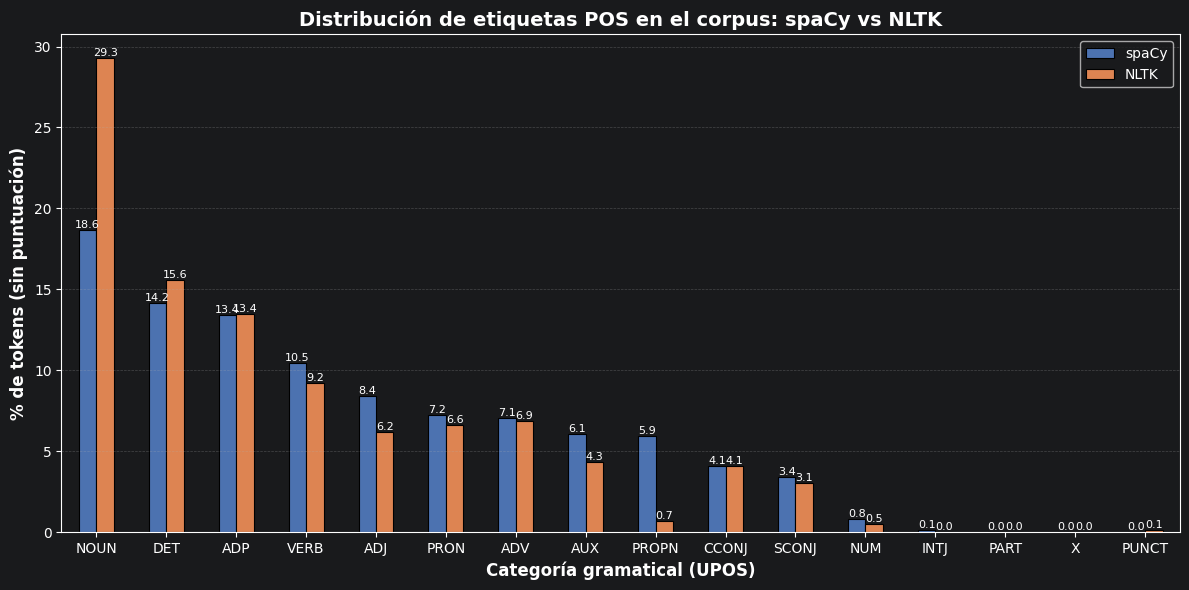

In [18]:
# Gráfico de la demo de clase, aplicado al corpus y comparando ambas herramientas
dist = pd.DataFrame({
    "spaCy": palabras["upos_spacy"].value_counts(normalize=True) * 100,
    "NLTK": palabras["upos_nltk"].value_counts(normalize=True) * 100,
}).fillna(0).sort_values("spaCy", ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
dist.plot.bar(ax=ax, color=["#4C72B0", "#DD8452"], edgecolor="black", linewidth=0.8, rot=0)
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.1f", fontsize=8)

ax.set_xlabel("Categoría gramatical (UPOS)", fontsize=12, fontweight="bold")
ax.set_ylabel("% de tokens (sin puntuación)", fontsize=12, fontweight="bold")
ax.set_title("Distribución de etiquetas POS en el corpus: spaCy vs NLTK", fontsize=14, fontweight="bold")
ax.grid(axis="y", alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()

Cuando una categoría tiene mucho más peso en NLTK que en spaCy, indica un sesgo del etiquetador. Por ejemplo, un exceso de NOUN en NLTK refleja las palabras desconocidas que recibieron la etiqueta por defecto